# 1.0 Overview of the MusicEval-full dataset

In [13]:
from pathlib import Path
import pandas as pd

dataset_path = Path("../data/MusicEval-full")

train_df = pd.read_csv(
    dataset_path / "sets" / "train_mos_list.txt",
    header=None,
    names=["filename", "musical_impression", "alignment"],
)
test_df = pd.read_csv(
    dataset_path / "sets" / "test_mos_list.txt",
    header=None,
    names=["filename", "musical_impression", "alignment"],
)
train_df.head()

,filename,musical_impression,alignment
0,audiomos2025-track1-S002_P044.wav,4.8,4.0
1,audiomos2025-track1-S030_P094.wav,2.2,2.0
2,audiomos2025-track1-S017_P082.wav,2.8,2.8
3,audiomos2025-track1-S023_P051.wav,2.2,2.6
4,audiomos2025-track1-S021_P019.wav,3.4,3.6


In [14]:
def parse_filename(filename: str) -> dict:
    # audiomos2025-track1-S019_P088.wav
    parts = filename.split(".")[0].split("_")
    return {
        "system": parts[0].split("-")[-1],
        "prompt": parts[1]
    }

train_df = pd.concat([train_df, train_df["filename"].apply(parse_filename).apply(pd.Series)], axis=1)
test_df = pd.concat([test_df, test_df["filename"].apply(parse_filename).apply(pd.Series)], axis=1)

prompts per system

<Axes: title={'center': 'Train'}, xlabel='system'>

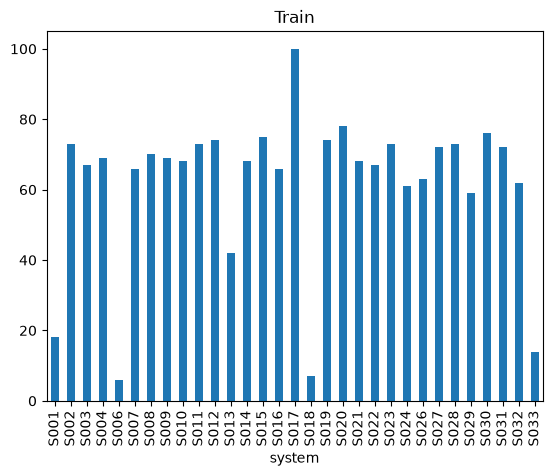

In [27]:
train_df.value_counts('system').sort_index().plot(kind='bar', title='Train')

<Axes: title={'center': 'Test'}, xlabel='system'>

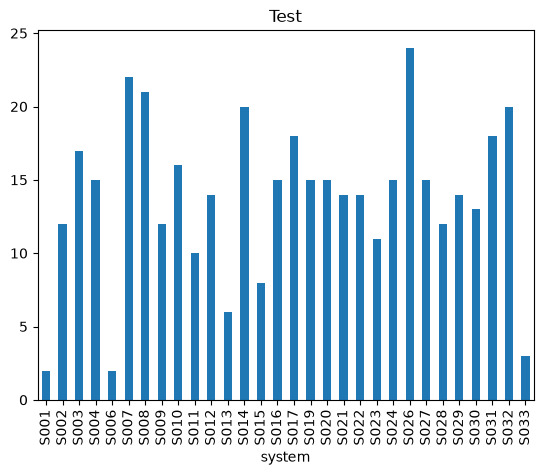

In [28]:
test_df.value_counts("system").sort_index().plot(kind="bar", title="Test")

distribution of ratings accross systems (generator models)

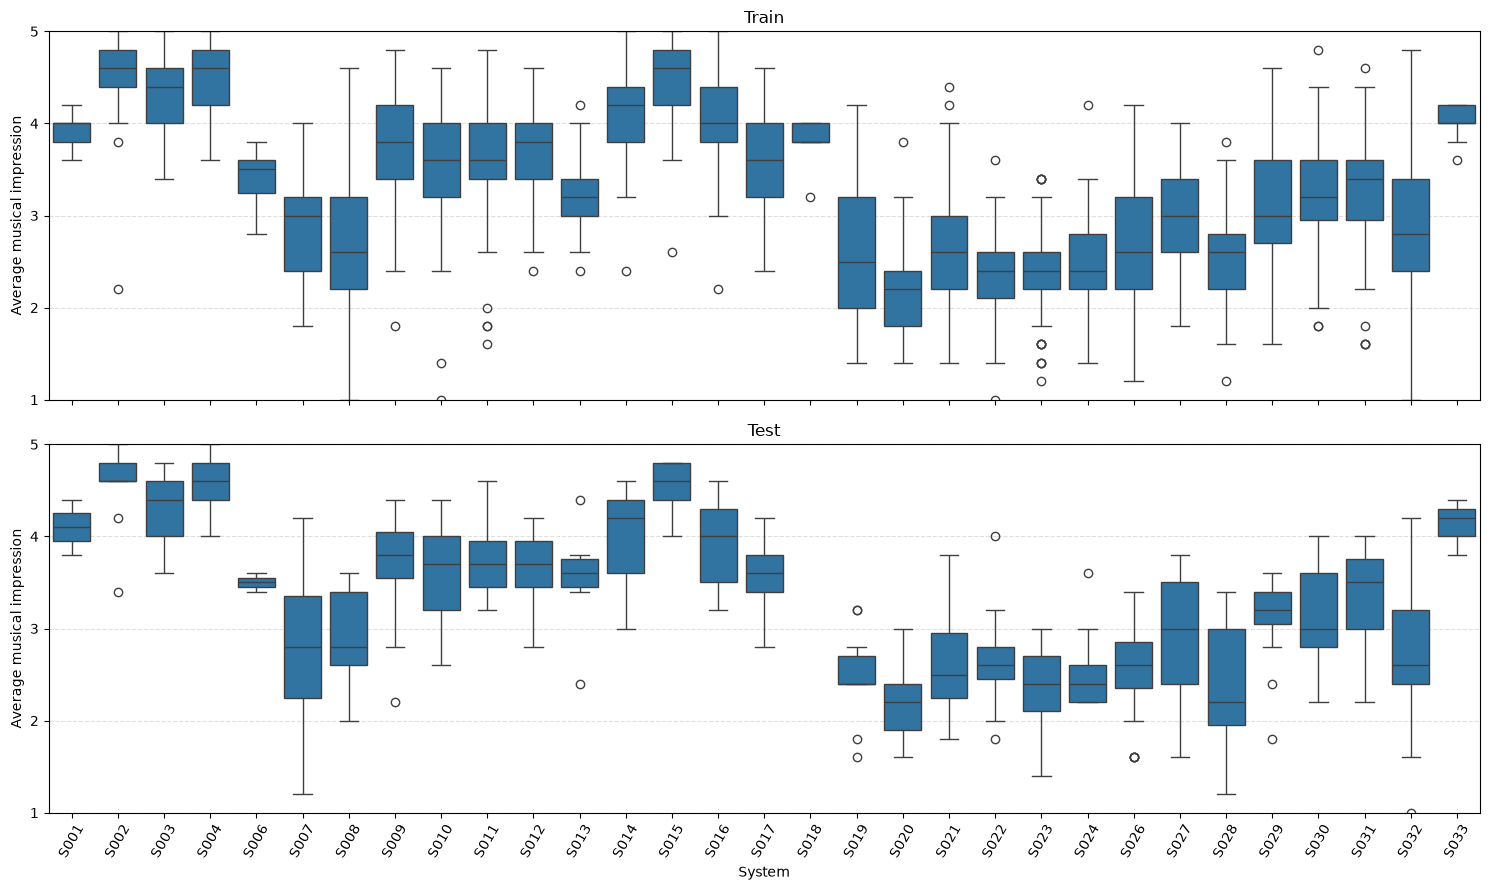

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True, sharey=True)

order = sorted(
    set(train_df["system"]) | set(test_df["system"]),
    key=lambda system: int(system[1:]),
)

for ax, frame, title in zip(axes, [train_df, test_df], ["Train", "Test"]):
    sns.boxplot(
        data=frame,
        x="system",
        y="musical_impression",
        order=order,
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("System")
    ax.set_ylabel("Average musical impression")
    ax.set_ylim(1, 5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

Sample the heldout systems for evaluation if the model is corelating on unseed generators.

In [29]:
heldout_frac = 0.2

heldout_systems = test_df["system"].drop_duplicates().sample(frac=heldout_frac, random_state=42)
heldout_systems

108    S006
24     S023
50     S015
28     S008
11     S019
12     S002
Name: system, dtype: object

In [33]:
train_size = train_df.shape[0]
heldout_train_size = train_df[train_df["system"].isin(heldout_systems)].shape[0]

print(f"Original train size: {train_size}")
print(f"Heldout train size: {heldout_train_size} ({heldout_train_size / train_size:.2%})")

Original train size: 1923
Heldout train size: 371 (19.29%)
